# 04. Feature Engineering & Selection
**Project:** Academic Sports Machine Learning Project  
**Domain:** Cricket Player Performance Analytics  
**Course Context:** Module 2 & 3 (Feature Engineering, Mutual Information & Tree-Based Feature Selection)  

---

## 1. Objectives & Academic Rationale
Raw cricket statistics like raw runs or wickets do not capture composite match impact. A score of 40 runs off 15 balls has a dramatically different match impact than 40 runs off 60 balls.
In this notebook:
1. We formulate domain-specific composite features:
   - **Batting Impact**: $Runs \times (Strike\_Rate / 100)$
   - **Bowling Impact**: $Wickets \times \frac{10}{Economy + 1}$
   - **Boundary Run Ratio**: $\frac{4 \times Fours + 6 \times Sixes}{Runs + 1}$
   - **Form-Consistency Index**: $(Recent\_Form / 100) \times (Consistency\_Score / 100)$
   - **Pressure Resilience**: $\frac{Fitness\_Score}{Pressure\_Score + 1}$
   - **All-Round Contribution Index**: Multi-discipline aggregate.
2. Fit feature selection pipelines **strictly on the training split**.
3. Evaluate feature importance using Mutual Information ($I(X; Y)$) and Random Forest importances.
4. Export the finalized engineered feature matrices.


In [1]:
import sys
sys.path.append('..')

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
from sklearn.feature_selection import mutual_info_classif, SelectKBest
from sklearn.ensemble import RandomForestClassifier
from src.preprocessing import SportsDataPreprocessor, create_binary_target, split_data, load_raw_data
from src.feature_engineering import engineer_cricket_features
from src.utils import DATA_PROCESSED_DIR, FIGURES_DIR, TABLES_DIR, set_seed

set_seed(42)
FIGURES_DIR.mkdir(parents=True, exist_ok=True)
TABLES_DIR.mkdir(parents=True, exist_ok=True)

# Load raw data and re-split to maintain exact split integrity
df_raw = load_raw_data()
X_raw, y = create_binary_target(df_raw, threshold=60.0)
X_train_raw, X_test_raw, y_train, y_test = split_data(X_raw, y, test_size=0.2, random_state=42)
print(f"Raw train shape: {X_train_raw.shape}, Raw test shape: {X_test_raw.shape}")

ModuleNotFoundError: No module named 'pandas'

## 2. Engineering Cricket Domain Features
We apply domain transformations to both train and test partitions independently.

In [2]:
X_train_eng = engineer_cricket_features(X_train_raw)
X_test_eng = engineer_cricket_features(X_test_raw)

new_features = ['Batting_Impact', 'Bowling_Impact', 'Boundary_Run_Ratio', 'Form_Consistency_Index', 'Pressure_Resilience', 'All_Round_Index']
print("Engineered domain features successfully created:")
print(X_train_eng[new_features].describe().T[['mean', 'std', 'min', '50%', 'max']].round(2))

Engineered domain features successfully created:
                         mean    std   min    50%     max
Batting_Impact          85.49  42.05  0.00  83.47  247.20
Bowling_Impact           3.07   4.34  0.00   2.44   70.00
Boundary_Run_Ratio       0.77   1.07  0.00   0.69   32.00
Form_Consistency_Index   0.38   0.15  0.00   0.37    1.00
Pressure_Resilience      1.22   0.44  0.34   1.13    6.48
All_Round_Index          7.26   3.33  0.08   7.06   22.10


## 3. Visualizing Engineered Feature Distributions

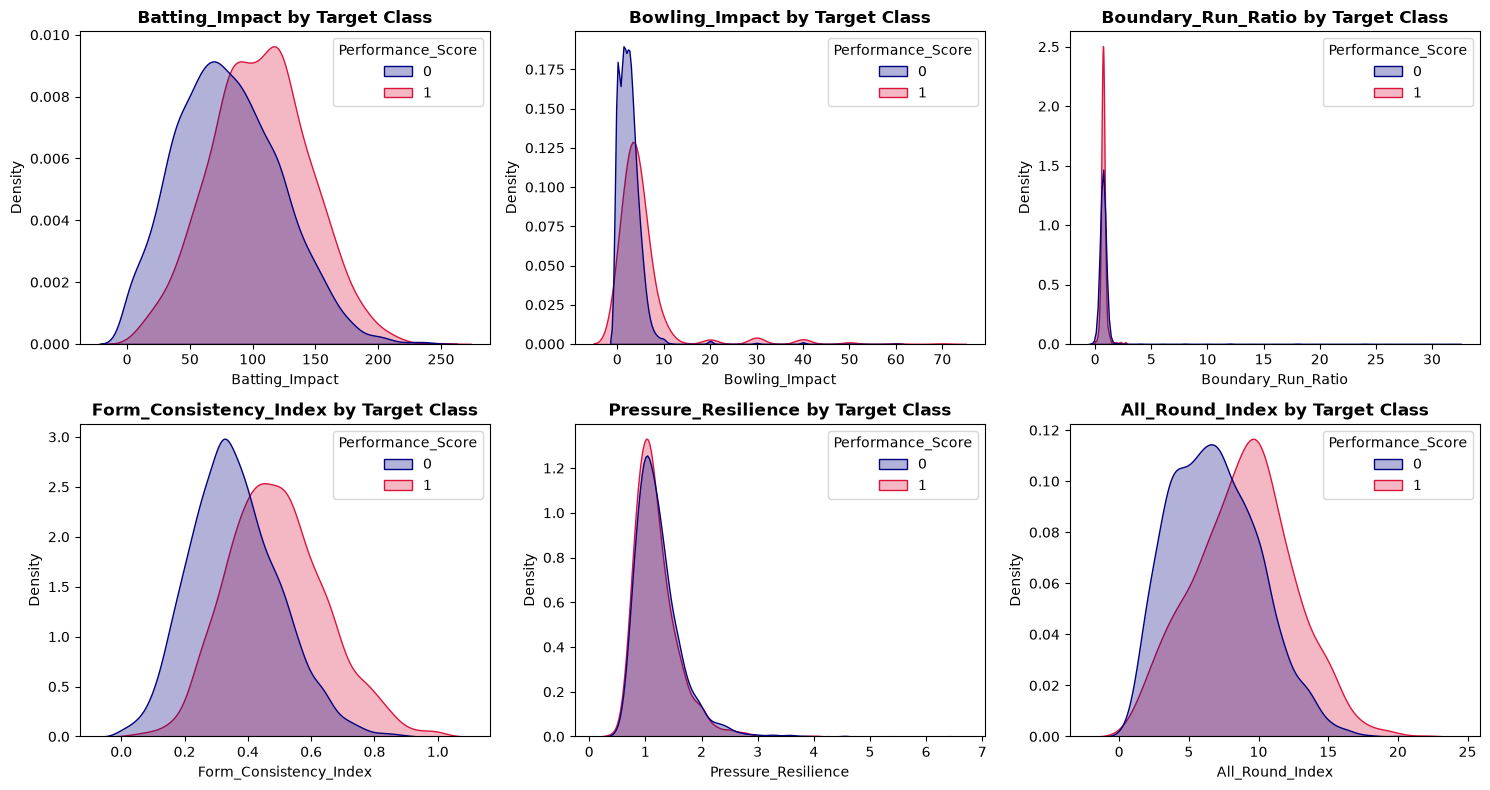

In [3]:
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
axes = axes.flatten()

for i, feat in enumerate(new_features):
    sns.kdeplot(data=X_train_eng, x=feat, hue=y_train, common_norm=False, palette=['navy', 'crimson'], ax=axes[i], fill=True, alpha=0.3)
    axes[i].set_title(f"{feat} by Target Class", fontweight='bold')

plt.tight_layout()
fig.savefig(FIGURES_DIR / "feature_engineering_distributions.png", dpi=300)
plt.show()

## 4. Full Preprocessing on Engineered Dataset
Applying `SportsDataPreprocessor` to scale numerical features (including new ones) and encode categorical attributes.

In [4]:
preprocessor_eng = SportsDataPreprocessor(sr_cap=400.0)
preprocessor_eng.fit(X_train_eng)

X_train_proc = preprocessor_eng.transform(X_train_eng)
X_test_proc = preprocessor_eng.transform(X_test_eng)

print(f"Transformed Train Features: {X_train_proc.shape}")
print(f"Transformed Test Features:  {X_test_proc.shape}")

Transformed Train Features: (8000, 88)
Transformed Test Features:  (2000, 88)


## 5. Feature Selection via Mutual Information
Mutual Information measures the reduction in uncertainty for the target variable given knowledge of a feature:
$$I(X; Y) = \sum_{x, y} P(x, y) \log \frac{P(x, y)}{P(x) P(y)}$$
Unlike linear correlation, Mutual Information captures non-linear dependencies.

--- Top 15 Features by Mutual Information ---
               Feature  MI_Score
Form_Consistency_Index  0.058041
           Recent_Form  0.056801
           Strike_Rate  0.053986
  Previous_Performance  0.049265
        Bowling_Impact  0.044089
       All_Round_Index  0.036465
               Wickets  0.027702
        Batting_Impact  0.026506
               Economy  0.023967
       Batting_Average  0.021605
          Overs_Bowled  0.014234
           Balls_Faced  0.012892
         Runs_Conceded  0.011206
      Match_Format_T20  0.010516
                 Fours  0.009359


C:\Users\chvis\AppData\Local\Temp\ipykernel_17620\99171607.py:13: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=mi_df.head(15), x='MI_Score', y='Feature', palette='viridis', ax=ax)


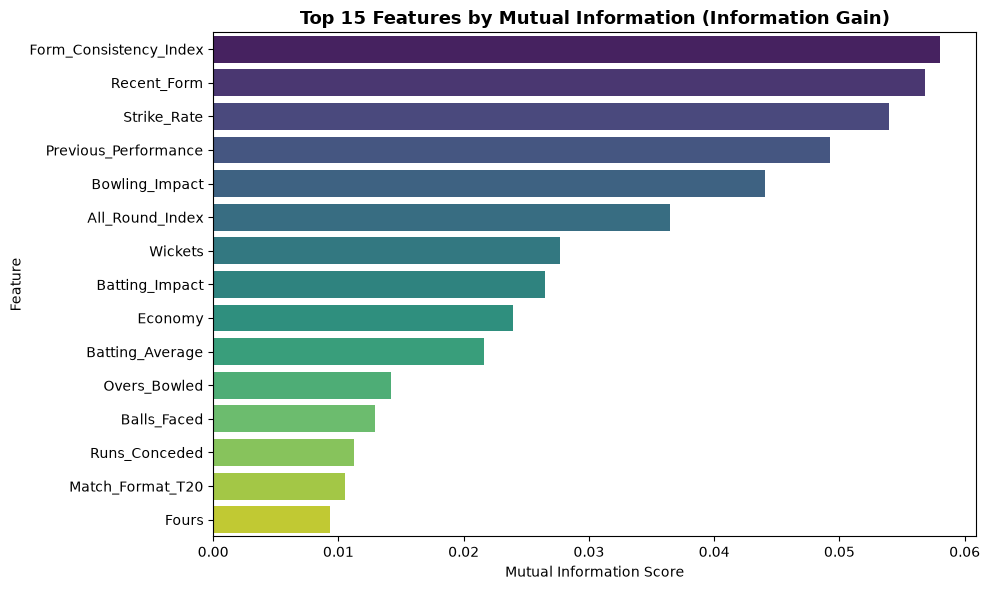

In [5]:
mi_scores = mutual_info_classif(X_train_proc, y_train, random_state=42)
mi_df = pd.DataFrame({
    'Feature': X_train_proc.columns,
    'MI_Score': mi_scores
}).sort_values('MI_Score', ascending=False).reset_index(drop=True)

print("--- Top 15 Features by Mutual Information ---")
print(mi_df.head(15).to_string(index=False))
mi_df.to_csv(TABLES_DIR / "mutual_info_rankings.csv", index=False)

# Plot top 15 features
fig, ax = plt.subplots(figsize=(10, 6))
sns.barplot(data=mi_df.head(15), x='MI_Score', y='Feature', palette='viridis', ax=ax)
ax.set_title("Top 15 Features by Mutual Information (Information Gain)", fontsize=13, fontweight='bold')
ax.set_xlabel("Mutual Information Score")
plt.tight_layout()
fig.savefig(FIGURES_DIR / "mutual_info_top_features.png", dpi=300)
plt.show()

## 6. Tree-Based Feature Importance Ranking
Using a Random Forest model on the training set to rank Gini impurity reduction.

In [6]:
rf_ranker = RandomForestClassifier(n_estimators=100, max_depth=10, random_state=42, n_jobs=-1)
rf_ranker.fit(X_train_proc, y_train)

rf_fi_df = pd.DataFrame({
    'Feature': X_train_proc.columns,
    'RF_Importance': rf_ranker.feature_importances_
}).sort_values('RF_Importance', ascending=False).reset_index(drop=True)

print("--- Top 15 Features by Random Forest Importance ---")
print(rf_fi_df.head(15).to_string(index=False))
rf_fi_df.to_csv(TABLES_DIR / "rf_feature_importances.csv", index=False)

--- Top 15 Features by Random Forest Importance ---
               Feature  RF_Importance
Form_Consistency_Index       0.088856
           Strike_Rate       0.088041
           Recent_Form       0.083460
  Previous_Performance       0.075841
        Bowling_Impact       0.072202
       All_Round_Index       0.052030
           Balls_Faced       0.050178
       Batting_Average       0.047122
        Batting_Impact       0.046220
               Economy       0.038125
               Wickets       0.035956
                  Runs       0.025632
         Runs_Conceded       0.024460
          Overs_Bowled       0.022330
        Pressure_Score       0.022273


## 7. Saving Engineered Datasets for Modeling

In [7]:
X_train_proc.to_csv(DATA_PROCESSED_DIR / "train_features_engineered.csv", index=False)
X_test_proc.to_csv(DATA_PROCESSED_DIR / "test_features_engineered.csv", index=False)
print("[SUCCESS] Engineered train and test datasets saved to data/processed/")

[SUCCESS] Engineered train and test datasets saved to data/processed/


## 8. Academic Viva Questions & Defense Notes

### Q1: Why is Mutual Information preferred over Pearson correlation for feature selection?
**Defense:** Pearson correlation evaluates only linear relationships ($r \in [-1, 1]$). In contrast, Mutual Information is an information-theoretic measure that quantifies arbitrary non-linear associations, capturing complex dependencies between player attributes and match outcomes without assuming a linear response.

### Q2: What domain logic justifies the Batting and Bowling Impact features?
**Defense:** Raw runs do not account for innings length or strike rate; a player scoring 30 runs off 10 balls adds more win probability than 30 runs off 50 balls. Similarly, Bowling Impact weights wickets inversely by economy rate, rewarding bowlers who take wickets while containing runs.
